# Chapter 9: AI in Portfolio Optimization

Companion notebook for Chapter 9 of *Mastering AI-Powered Finance* (`Overleaf/Book 1`). It was built from Chapter 7 of the full manuscript (Equity Investing and Portfolio Management); the source references below point to that manuscript.

Notebook extracted from `Overleaf/Final Project/Chapter 7 - Equity Investing and Portfolio Management/main.tex`.

This notebook turns the chapter code examples into a student-facing workflow. Code cells follow the order used in the chapter; Markdown cells identify the source sections and explain how to interpret the computed output.

Run the notebook from top to bottom. Some examples are intentionally small and synthetic; examples that call external services require the dependency or credential noted below.

**Data:** prices and fundamentals load from the bundled snapshots in `data/`, so the notebook runs offline and reproduces the figures in the book. Set `REFRESH_MARKET_DATA=1` to fetch current provider data instead, and expect different results. The optional Fama-French example needs internet access and the pandas-datareader package.

**Review notes:** The fundamentals snapshot is dated 21 September 2026 and supports an illustrative cross-sectional ranking only. Because that date falls after the 2019-2023 price window, it is not point-in-time information for the backtest period. The default backtest uses only lagged price factors (momentum and low volatility). A callable supplying as-reported fundamentals known at each signal date can enable the full factor model. The fixed stock universe still has survivorship bias. Month-end execution after a full month of decision lag, a constant risk-free assumption, simple linear trading costs, and frictionless cash are teaching assumptions, so the results are not evidence of investable alpha. Unverified historical output tables were removed; compute results from the code. Missing price observations are not filled, and held assets with missing realized returns raise an error. Supply complete calendar months for evaluation.

The original, more detailed workflow is preserved, with corrections to data handling, timing, trading costs, optimization checks, risk limits, and metrics.
Manuscript synchronization (2026-09-21): concise printed algorithms now match this expanded notebook. Obsolete output tables were removed. With the bundled snapshots in place the results are reproducible and do match the figures printed in the chapter.


In [1]:
# Common notebook setup
import matplotlib.pyplot as plt
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.grid'] = True
# Grayscale defaults, matching the printed book: black, mid and light gray,
# each with its own line style so series stay distinguishable in print.
from cycler import cycler
plt.rcParams['axes.prop_cycle'] = cycler(color=['0.0', '0.45', '0.7'], linestyle=['-', '--', ':'])
plt.rcParams['image.cmap'] = 'Greys'

## Recap: stock selection from Chapter 8

The cells in this recap rerun the Chapter 8 tutorial (data loading, returns, factor ranking and stock selection) so that this notebook runs on its own. The Chapter 9 tutorial starts after the recap.


## AI Tutorial: Stock Selection and Portfolio Construction

### Optional environment installation

```bash
pip install numpy pandas yfinance scipy scikit-learn matplotlib pandas-datareader
```


## AI Tutorial: Stock Selection and Portfolio Construction / Environment Setup and Data Acquisition

### Code example 1
Source line: `Overleaf/Final Project/Chapter 7 - Equity Investing and Portfolio Management/main.tex`

In [2]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import yfinance as yf
from scipy.optimize import minimize
from scipy import stats
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt
from datetime import datetime, timedelta
import warnings


# Define a fixed illustrative investment universe: 52 stocks across sectors.
# Historical membership is not reconstructed, so survivorship bias remains.
UNIVERSE = [
    # Technology
    'AAPL', 'MSFT', 'GOOGL', 'META', 'NVDA', 'AVGO', 'CSCO', 'ORCL',
    # Healthcare
    'JNJ', 'UNH', 'PFE', 'ABBV', 'MRK', 'LLY', 'TMO', 'ABT',
    # Financials
    'JPM', 'BAC', 'WFC', 'GS', 'MS', 'BLK', 'AXP', 'C',
    # Consumer
    'AMZN', 'HD', 'MCD', 'NKE', 'SBUX', 'TGT', 'COST', 'WMT',
    # Industrials
    'CAT', 'HON', 'UPS', 'RTX', 'LMT', 'GE', 'MMM', 'BA',
    # Energy & Materials
    'XOM', 'CVX', 'COP', 'SLB', 'LIN', 'APD', 'ECL', 'SHW',
    # Utilities & REITs
    'NEE', 'DUK', 'SO', 'PLD'
]

# Benchmark: S&P 500 ETF
BENCHMARK = 'SPY'

def download_stock_data(tickers, start_date, end_date):
    """
    Download adjusted close prices for a list of tickers.

    Parameters:
    -----------
    tickers : list
        Stock ticker symbols
    start_date, end_date : str
        Date range in 'YYYY-MM-DD' format

    Returns:
    --------
    pd.DataFrame : Adjusted close prices, stocks as columns
    """
    all_tickers = list(dict.fromkeys(list(tickers) + [BENCHMARK]))
    snapshot = Path('data/prices_2019_2024.csv')
    if snapshot.exists() and os.environ.get('REFRESH_MARKET_DATA') != '1':
        data = pd.read_csv(snapshot, index_col=0, parse_dates=True)
        data = data.reindex(columns=all_tickers).sort_index()
    else:
        raw = yf.download(all_tickers, start=start_date, end=end_date,
                          auto_adjust=False, progress=False)
        if raw is None or raw.empty or 'Adj Close' not in raw.columns.get_level_values(0):
            raise ValueError("No adjusted prices returned; check the data service.")
        data = raw['Adj Close'].reindex(columns=all_tickers).sort_index()
    if data[BENCHMARK].dropna().empty:
        raise ValueError("Benchmark adjusted prices are unavailable.")
    if (data <= 0).any().any() or np.isinf(data.to_numpy()).any():
        raise ValueError("Adjusted prices must be positive and finite where observed.")
    # Do not select stocks using missingness over the full future test period.
    # Each rebalance will use only its trailing history to establish eligibility.
    return data

# Download 5 years of data for backtesting
END_DATE = '2024-01-01'
START_DATE = '2019-01-01'

print("Downloading stock data...")
prices = download_stock_data(UNIVERSE, START_DATE, END_DATE)
print(f"Downloaded data for {len(prices.columns)-1} stocks plus benchmark")
print(f"Date range: {prices.index[0].date()} to {prices.index[-1].date()}")
print(f"Total trading days: {len(prices)}")

Downloaded data for 52 stocks plus benchmark
Date range: 2019-01-02 to 2023-12-29
Total trading days: 1258


### Reading the computed output

Run the preceding cell for the current calculation. The old manuscript table has been removed because it was not generated by the corrected workflow and contained inconsistent rankings or arithmetic. The current fundamental snapshot is a mechanics demonstration; historical results use lagged price factors unless an as-reported fundamentals callback is supplied.


## AI Tutorial: Stock Selection and Portfolio Construction / Environment Setup and Data Acquisition / Computing Returns and Fundamental Data

### Code example 2
Source line: `Overleaf/Final Project/Chapter 7 - Equity Investing and Portfolio Management/main.tex`

In [3]:
def compute_returns(prices):
    """Compute daily and monthly returns from prices."""
    daily_returns = prices.pct_change(fill_method=None).iloc[1:]

    # Monthly returns (last trading day of each month)
    # Keep the actual last row: resample().last() would skip missing closes.
    monthly_prices = prices.resample(pd.offsets.MonthEnd()).agg(lambda x: x.iloc[-1] if len(x) else np.nan)
    monthly_returns = monthly_prices.pct_change(fill_method=None).iloc[1:]

    return daily_returns, monthly_returns

daily_returns, monthly_returns = compute_returns(prices)

def get_fundamental_data(tickers):
    """
    Retrieve fundamental data for factor construction.

    Returns DataFrame with: P/E, P/B, ROE, Debt/Equity, Market Cap
    """
    # A pinned snapshot with a stated as-of date. yf.Ticker().info returns
    # whatever the market looks like today, with no historical as-of, so a
    # live fetch silently changes every ranking and weight below.
    snapshot = Path('data/fundamentals_snapshot.csv')
    if snapshot.exists() and os.environ.get('REFRESH_MARKET_DATA') != '1':
        return pd.read_csv(snapshot, index_col='ticker')

    fundamentals = []

    for ticker in tickers:
        if ticker == BENCHMARK:
            continue
        try:
            stock = yf.Ticker(ticker)
            info = stock.info

            fundamentals.append({
                'ticker': ticker,
                'pe_ratio': info.get('trailingPE', np.nan),
                'pb_ratio': info.get('priceToBook', np.nan),
                'roe': info.get('returnOnEquity', np.nan),
                'debt_to_equity': info.get('debtToEquity', np.nan),
                'market_cap': info.get('marketCap', np.nan),
                'dividend_yield': info.get('dividendYield', np.nan),
                'beta': info.get('beta', np.nan),
                'profit_margin': info.get('profitMargins', np.nan)
            })
        except Exception as e:
            warnings.warn(f'Fundamentals unavailable for {ticker}: {e}')

    if not fundamentals:
        raise ValueError('No fundamentals returned; retry the live snapshot separately.')
    df = pd.DataFrame(fundamentals).set_index('ticker')
    return df

print("Fetching fundamental data...")
fundamentals = get_fundamental_data(UNIVERSE)
print(f"Retrieved fundamentals for {len(fundamentals)} stocks")
print("\nSample fundamental data:")
print(fundamentals[['pe_ratio', 'pb_ratio', 'roe', 'market_cap']].head(10))

Fetching fundamental data...
Retrieved fundamentals for 52 stocks

Sample fundamental data:
         pe_ratio   pb_ratio      roe     market_cap
ticker                                              
AAPL    38.918484  46.057064  1.48751  4947135430656
MSFT    27.913746   8.421221  0.34039  3724727812096
GOOGL   17.819778   6.974419  0.48676  4341260091392
META    27.908321   7.230248  0.29848  1888326254592
NVDA    28.745892  23.977646  1.17211  5490544738304
AVGO    46.316730  17.367111  0.44245  1731204612096
CSCO    33.471474   8.746763  0.27319   439440736256
ORCL    23.285265   7.267391  0.41192   449206222848
JNJ     31.297330   7.637173  0.25742   649395372032
UNH     24.249197   3.470827  0.14153   338895896576


### Reading the computed output

Run the preceding cell for the current calculation. The old manuscript table has been removed because it was not generated by the corrected workflow and contained inconsistent rankings or arithmetic. The current fundamental snapshot is a mechanics demonstration; historical results use lagged price factors unless an as-reported fundamentals callback is supplied.


## AI Tutorial: Stock Selection and Portfolio Construction / Factor-Based Stock Ranking and Screening

### Code example 3
Source line: `Overleaf/Final Project/Chapter 7 - Equity Investing and Portfolio Management/main.tex`

In [4]:
def compute_momentum_factor(returns, lookback=12, skip=1):
    """
    Compute momentum factor: cumulative return over lookback months,
    skipping the most recent month to avoid reversal effects.

    Parameters:
    -----------
    returns : pd.DataFrame
        Monthly returns
    lookback : int
        Lookback period in months (default 12)
    skip : int
        Months to skip at end (default 1)

    Returns:
    --------
    pd.Series : Momentum scores for each stock
    """
    if lookback < 1 or skip < 0:
        raise ValueError('lookback must be positive and skip nonnegative.')
    if len(returns) < lookback + skip:
        return pd.Series(dtype=float)

    # Use returns from t-lookback-skip to t-skip
    momentum_returns = returns.iloc[-(lookback+skip):len(returns)-skip]

    # Cumulative return over the period
    cumulative = (1 + momentum_returns).prod(min_count=lookback) - 1

    return cumulative

def compute_volatility_factor(returns, lookback=12):
    """
    Compute volatility factor: annualized standard deviation.
    Lower volatility is considered better (negative factor).
    """
    if len(returns) < lookback:
        return pd.Series(dtype=float)

    recent_returns = returns.iloc[-lookback:]
    volatility = recent_returns.std() * np.sqrt(12)  # Annualize

    return -volatility  # Negative so higher score = lower vol

def rank_normalize(series):
    """
    Convert values to percentile ranks (0 to 1).
    Handles NaN values by excluding them from ranking.
    """
    return series.rank(pct=True, na_option='keep')

def compute_composite_score(fundamentals, monthly_returns, weights=None):
    """
    Compute composite factor score for stock ranking.

    Factors:
    - Value: Low P/E, low P/B (inverted and ranked)
    - Quality: High ROE, low debt/equity, high profit margin
    - Momentum: 12 monthly returns, excluding the most recent month (13-month history)
    - Low Volatility: Lower historical volatility

    Parameters:
    -----------
    fundamentals : pd.DataFrame
        Fundamental data
    monthly_returns : pd.DataFrame
        Monthly return history
    weights : dict, optional
        Factor weights (default: equal weight)

    Returns:
    --------
    pd.DataFrame : Factor scores and composite ranking
    """
    if weights is None:
        weights = {
            'value': 0.25,
            'quality': 0.25,
            'momentum': 0.30,
            'low_vol': 0.20
        }

    factor_names = ['value', 'quality', 'momentum', 'low_vol']
    if set(weights) != set(factor_names) or any(v < 0 for v in weights.values()) or not np.isclose(sum(weights.values()), 1):
        raise ValueError('Factor weights must be nonnegative and sum to one.')
    scores = pd.DataFrame(index=fundamentals.index)

    # Value factor: inverse of P/E and P/B (lower is better)
    # Nonpositive valuation ratios are not cheapness signals. Clipping reduces
    # outlier impact but ties all observations above each cap (information lost).
    pe_capped = fundamentals['pe_ratio'].where(fundamentals['pe_ratio'] > 0).clip(upper=100)
    pb_capped = fundamentals['pb_ratio'].where(fundamentals['pb_ratio'] > 0).clip(upper=50)

    scores['value_pe'] = rank_normalize(-pe_capped)
    scores['value_pb'] = rank_normalize(-pb_capped)
    scores['value'] = (scores['value_pe'] + scores['value_pb']) / 2

    # Quality factor: high ROE, low leverage, high margins
    scores['quality_roe'] = rank_normalize(fundamentals['roe'])
    scores['quality_debt'] = rank_normalize(-fundamentals['debt_to_equity'].where(
        fundamentals['debt_to_equity'] >= 0).clip(upper=500))
    scores['quality_margin'] = rank_normalize(fundamentals['profit_margin'])
    scores['quality'] = (scores['quality_roe'] + scores['quality_debt'] +
                         scores['quality_margin']) / 3

    # Momentum factor
    momentum = compute_momentum_factor(monthly_returns.drop(columns=[BENCHMARK],
                                       errors='ignore'))
    scores['momentum'] = rank_normalize(momentum)

    # Low volatility factor
    low_vol = compute_volatility_factor(monthly_returns.drop(columns=[BENCHMARK],
                                        errors='ignore'))
    scores['low_vol'] = rank_normalize(low_vol)

    # Composite score (weighted average of factor ranks)
    scores['composite'] = (
        weights['value'] * scores['value'].fillna(0.5) +
        weights['quality'] * scores['quality'].fillna(0.5) +
        weights['momentum'] * scores['momentum'].fillna(0.5) +
        weights['low_vol'] * scores['low_vol'].fillna(0.5)
    )

    # Final rank
    scores['rank'] = scores['composite'].rank(ascending=False)

    return scores.sort_values('composite', ascending=False)

# Compute factor scores
# This snapshot mixes live fundamentals with the fixed historical price window.
# It demonstrates ranking mechanics, not a historical trade recommendation.
ranking_universe = fundamentals.index.intersection(monthly_returns.columns)
ranking_universe = ranking_universe[monthly_returns[ranking_universe].tail(13).notna().all()]
factor_scores = compute_composite_score(fundamentals.loc[ranking_universe], monthly_returns[ranking_universe])
print("Factor-Based Stock Ranking (Top 15):")
print(factor_scores[['value', 'quality', 'momentum', 'low_vol',
                     'composite', 'rank']].head(15).round(3))

Factor-Based Stock Ranking (Top 15):
       value  quality  momentum  low_vol  composite  rank
MSFT   0.399    0.828     0.885    0.769      0.726   1.0
GOOGL  0.597    0.918     0.846    0.385      0.709   2.0
LIN    0.441    0.563     0.769    0.981      0.678   3.0
JPM    0.849      NaN     0.750    0.558      0.674   4.0
META   0.449    0.761     1.000    0.288      0.660   5.0
AMZN   0.559    0.677     0.904    0.308      0.642   6.0
SO     0.732    0.317     0.673    0.808      0.626   7.0
MCD      NaN      NaN     0.615    0.923      0.619   8.0
NVDA   0.277    0.979     0.981    0.019      0.612   9.0
DUK    0.871    0.318     0.385    0.942      0.601  10.0
COP    0.860    0.558     0.404    0.596      0.595  11.0
UNH    0.611    0.355     0.558    0.904      0.590  12.0
ORCL   0.478    0.540     0.865    0.365      0.587  13.0
HON    0.816    0.558     0.250    0.827      0.584  14.0
GE     0.180    0.598     0.962    0.481      0.579  15.0


### Reading the computed output

Run the preceding cell for the current calculation. The old manuscript table has been removed because it was not generated by the corrected workflow and contained inconsistent rankings or arithmetic. The current fundamental snapshot is a mechanics demonstration; historical results use lagged price factors unless an as-reported fundamentals callback is supplied.


## AI Tutorial: Stock Selection and Portfolio Construction / Factor-Based Stock Ranking and Screening / Stock Selection: Top Quintile

### Code example 4
Source line: `Overleaf/Final Project/Chapter 7 - Equity Investing and Portfolio Management/main.tex`

In [5]:
def select_stocks(factor_scores, n_stocks=None, percentile=0.20):
    """
    Select top-ranked stocks based on factor scores.

    Parameters:
    -----------
    factor_scores : pd.DataFrame
        Factor scores with 'composite' column
    n_stocks : int, optional
        Number of stocks to select (overrides percentile)
    percentile : float
        Top percentile to select (default 0.20 = top 20%)

    Returns:
    --------
    list : Selected stock tickers
    """
    if not 0 < percentile <= 1 or (n_stocks is not None and n_stocks < 1):
        raise ValueError('Select a positive stock count or percentile in (0, 1].')
    sorted_scores = factor_scores.dropna(subset=['composite']).sort_values('composite', ascending=False)
    if sorted_scores.empty:
        raise ValueError('No eligible stocks to select.')

    if n_stocks is None:
        n_stocks = max(10, int(len(sorted_scores) * percentile))

    selected = sorted_scores.head(n_stocks).index.tolist()
    return selected

# Select top quintile
selected_stocks = select_stocks(factor_scores, percentile=0.20)
print(f"\nSelected Portfolio ({len(selected_stocks)} stocks):")
print(selected_stocks)

# Get factor exposures for selected stocks
selected_scores = factor_scores.loc[selected_stocks]
print(f"\nAverage factor scores for selected portfolio:")
print(selected_scores[['value', 'quality', 'momentum', 'low_vol']].mean().round(3))

print(f"\nAverage factor scores for full universe:")
print(factor_scores[['value', 'quality', 'momentum', 'low_vol']].mean().round(3))


Selected Portfolio (10 stocks):
['MSFT', 'GOOGL', 'LIN', 'JPM', 'META', 'AMZN', 'SO', 'MCD', 'NVDA', 'DUK']

Average factor scores for selected portfolio:
value       0.575
quality     0.670
momentum    0.781
low_vol     0.598
dtype: float64

Average factor scores for full universe:
value       0.517
quality     0.512
momentum    0.510
low_vol     0.510
dtype: float64


### Reading the computed output

Run the preceding cell for the current calculation. The old manuscript table has been removed because it was not generated by the corrected workflow and contained inconsistent rankings or arithmetic. The current fundamental snapshot is a mechanics demonstration; historical results use lagged price factors unless an as-reported fundamentals callback is supplied.


## Chapter 9 tutorial: portfolio optimization


## AI Tutorial: Stock Selection and Portfolio Construction / Mean-Variance Portfolio Optimization with Constraints

### Code example 5
Source line: `Overleaf/Final Project/Chapter 7 - Equity Investing and Portfolio Management/main.tex`

In [6]:
def estimate_expected_returns(returns, method='historical', shrinkage=0.5):
    """
    Estimate expected returns for optimization.

    Parameters:
    -----------
    returns : pd.DataFrame
        Historical returns
    method : str
        'historical' for sample mean, 'shrinkage' for shrunk estimates
    shrinkage : float
        Shrinkage intensity toward equal returns

    Returns:
    --------
    pd.Series : Expected return estimates
    """
    if method not in {'historical', 'shrinkage'} or not 0 <= shrinkage <= 1:
        raise ValueError('Unknown return estimator or invalid shrinkage intensity.')
    historical_mean = returns.mean() * 12  # Annualized

    if method == 'historical':
        return historical_mean

    elif method == 'shrinkage':
        # Shrink toward grand mean (reduces estimation error)
        grand_mean = historical_mean.mean()
        shrunk = shrinkage * grand_mean + (1 - shrinkage) * historical_mean
        return shrunk

    return historical_mean

def estimate_covariance(returns, method='sample', shrinkage_target='constant_corr'):
    """
    Estimate covariance matrix for optimization.

    Parameters:
    -----------
    returns : pd.DataFrame
        Historical returns
    method : str
        'sample' for sample covariance, 'shrinkage' for fixed-intensity shrinkage
    shrinkage_target : str
        Target for shrinkage ('constant_corr' or 'identity')

    Returns:
    --------
    pd.DataFrame : Covariance matrix estimate
    """
    if method not in {'sample', 'shrinkage'} or shrinkage_target not in {'constant_corr', 'identity'}:
        raise ValueError('Unknown covariance estimator or shrinkage target.')
    if len(returns) < 2 or returns.empty or not np.isfinite(returns.to_numpy()).all():
        raise ValueError('Covariance estimation requires complete, finite monthly returns.')
    sample_cov = returns.cov() * 12  # Annualized

    if method == 'sample':
        return sample_cov

    elif method == 'shrinkage':
        n = len(returns.columns)

        # Shrinkage target: constant correlation matrix
        if shrinkage_target == 'constant_corr':
            sample_corr = returns.corr().fillna(0)
            off_diagonal = sample_corr.to_numpy()[~np.eye(n, dtype=bool)]
            avg_corr = float(off_diagonal.mean()) if n > 1 else 0.0
            target_corr = np.full((n, n), avg_corr)
            np.fill_diagonal(target_corr, 1.0)

            std_devs = np.sqrt(np.diag(sample_cov))
            target = np.outer(std_devs, std_devs) * target_corr
            target = pd.DataFrame(target, index=sample_cov.index,
                                  columns=sample_cov.columns)
        else:
            # Identity scaled by average variance
            avg_var = np.diag(sample_cov).mean()
            target = pd.DataFrame(np.eye(n) * avg_var,
                                  index=sample_cov.index,
                                  columns=sample_cov.columns)

        # Fixed 20% shrinkage: a teaching heuristic, not estimated Ledoit-Wolf.
        # Higher intensity trades sample noise for bias toward the target.
        shrinkage_intensity = 0.2
        shrunk_cov = (1 - shrinkage_intensity) * sample_cov + shrinkage_intensity * target

        return shrunk_cov

    return sample_cov

def portfolio_performance(weights, expected_returns, cov_matrix, risk_free_rate=0.04):
    """Calculate portfolio expected return, volatility, and Sharpe ratio."""
    port_return = np.dot(weights, expected_returns)
    port_vol = np.sqrt(np.dot(weights.T, np.dot(cov_matrix, weights)))
    sharpe = (port_return - risk_free_rate) / port_vol if port_vol > 0 else np.nan
    return port_return, port_vol, sharpe

def optimize_portfolio(expected_returns, cov_matrix, risk_free_rate=0.04,
                       max_weight=0.20, min_weight=0.02, target_return=None):
    """
    Optimize portfolio weights using mean-variance optimization.

    Parameters:
    -----------
    expected_returns : pd.Series
        Expected returns for each asset
    cov_matrix : pd.DataFrame
        Covariance matrix
    risk_free_rate : float
        Risk-free rate for Sharpe calculation
    max_weight : float
        Maximum weight per stock
    min_weight : float
        Minimum weight per stock (if included)
    target_return : float, optional
        Target return constraint (if None, maximize Sharpe)

    Returns:
    --------
    dict : Optimization results including weights, return, vol, Sharpe
    """
    n = len(expected_returns)
    if n == 0 or not 0 <= min_weight <= max_weight <= 1 or n * min_weight > 1 + 1e-10 or n * max_weight < 1 - 1e-10:
        raise ValueError('Position bounds cannot form a fully invested portfolio.')
    cov_matrix = cov_matrix.loc[expected_returns.index, expected_returns.index]
    if not np.isfinite(expected_returns.to_numpy()).all() or not np.isfinite(cov_matrix.to_numpy()).all():
        raise ValueError('Optimizer inputs must be finite.')
    if not np.allclose(cov_matrix, cov_matrix.T) or np.linalg.eigvalsh(cov_matrix).min() < -1e-10:
        raise ValueError('Covariance must be symmetric positive semidefinite.')
    if target_return is not None:
        # Greedily allocate remaining capacity to obtain attainable return bounds.
        attainable = []
        for order in (np.argsort(expected_returns.to_numpy()), np.argsort(-expected_returns.to_numpy())):
            w = np.full(n, min_weight, dtype=float)
            for j in order:
                w[j] += min(max_weight - min_weight, max(0.0, 1 - w.sum()))
            attainable.append(float(w @ expected_returns.to_numpy()))
        if not attainable[0] - 1e-8 <= target_return <= attainable[1] + 1e-8:
            raise ValueError('Target return is infeasible under the position bounds.')
    init_weights = np.ones(n) / n

    # Objective: minimize negative Sharpe ratio (maximize Sharpe)
    def neg_sharpe(weights):
        ret, vol, sharpe = portfolio_performance(weights, expected_returns.values,
                                                  cov_matrix.values)
        return -(ret - risk_free_rate) / max(vol, 1e-12)

    # Objective for minimum variance
    def portfolio_variance(weights):
        return np.dot(weights.T, np.dot(cov_matrix.values, weights))

    # Constraints
    constraints = [
        {'type': 'eq', 'fun': lambda w: np.sum(w) - 1}  # Weights sum to 1
    ]

    if target_return is not None:
        constraints.append({
            'type': 'eq',
            'fun': lambda w: np.dot(w, expected_returns.values) - target_return
        })

    # Bounds: long-only with position limits
    bounds = tuple((min_weight, max_weight) for _ in range(n))

    # Optimize
    if target_return is None:
        result = minimize(neg_sharpe, init_weights, method='SLSQP',
                         bounds=bounds, constraints=constraints,
                         options={'maxiter': 1000, 'ftol': 1e-10})
    else:
        result = minimize(portfolio_variance, init_weights, method='SLSQP',
                         bounds=bounds, constraints=constraints,
                         options={'maxiter': 1000, 'ftol': 1e-10})

    if not result.success or abs(result.x.sum() - 1) > 1e-6 or (result.x < min_weight - 1e-6).any() or (result.x > max_weight + 1e-6).any():
        raise RuntimeError(f'Portfolio optimization failed: {result.message}')
    if target_return is not None and abs(result.x @ expected_returns.to_numpy() - target_return) > 1e-6:
        raise RuntimeError('Optimizer did not satisfy the target-return constraint.')
    optimal_weights = result.x
    opt_ret, opt_vol, opt_sharpe = portfolio_performance(
        optimal_weights, expected_returns.values, cov_matrix.values
    )

    return {
        'weights': pd.Series(optimal_weights, index=expected_returns.index),
        'return': opt_ret,
        'volatility': opt_vol,
        'sharpe': (opt_ret - risk_free_rate) / opt_vol if opt_vol > 0 else np.nan,
        'success': result.success
    }

# Get returns for selected stocks only
selected_returns = monthly_returns[selected_stocks].dropna()

# Estimate inputs
exp_returns = estimate_expected_returns(selected_returns, method='shrinkage',
                                         shrinkage=0.3)
cov_matrix = estimate_covariance(selected_returns, method='shrinkage')

print("Expected Returns (annualized):")
print(exp_returns.round(4))
print(f"\nRisk-free rate: 4.0%")

Expected Returns (annualized):
MSFT     0.2791
GOOGL    0.2261
LIN      0.2319
JPM      0.1902
META     0.2362
AMZN     0.1883
SO       0.1666
MCD      0.1723
NVDA     0.5385
DUK      0.1266
dtype: float64

Risk-free rate: 4.0%


### Reading the computed output

Run the preceding cell for the current calculation. The old manuscript table has been removed because it was not generated by the corrected workflow and contained inconsistent rankings or arithmetic. The current fundamental snapshot is a mechanics demonstration; historical results use lagged price factors unless an as-reported fundamentals callback is supplied.


## AI Tutorial: Stock Selection and Portfolio Construction / Mean-Variance Portfolio Optimization with Constraints / Optimization: Maximum Sharpe Ratio Portfolio

### Code example 6
Source line: `Overleaf/Final Project/Chapter 7 - Equity Investing and Portfolio Management/main.tex`

In [7]:
# Maximum Sharpe Ratio Portfolio
max_sharpe_result = optimize_portfolio(
    exp_returns, cov_matrix,
    risk_free_rate=0.04,
    max_weight=0.20,
    min_weight=0.02
)

print("Maximum Sharpe Ratio Portfolio:")
print("-" * 40)
print(f"Expected Return: {max_sharpe_result['return']:.2%}")
print(f"Volatility: {max_sharpe_result['volatility']:.2%}")
print(f"Sharpe Ratio: {max_sharpe_result['sharpe']:.3f}")
print(f"\nOptimal Weights:")
weights_sorted = max_sharpe_result['weights'].sort_values(ascending=False)
for ticker, weight in weights_sorted.items():
    print(f"  {ticker}: {weight:.1%}")

Maximum Sharpe Ratio Portfolio:
----------------------------------------
Expected Return: 27.94%
Volatility: 20.08%
Sharpe Ratio: 1.192

Optimal Weights:
  MSFT: 20.0%
  SO: 20.0%
  NVDA: 20.0%
  LIN: 19.4%
  MCD: 10.6%
  JPM: 2.0%
  GOOGL: 2.0%
  META: 2.0%
  AMZN: 2.0%
  DUK: 2.0%


### Reading the computed output

Run the preceding cell for the current calculation. The old manuscript table has been removed because it was not generated by the corrected workflow and contained inconsistent rankings or arithmetic. The current fundamental snapshot is a mechanics demonstration; historical results use lagged price factors unless an as-reported fundamentals callback is supplied.


## AI Tutorial: Stock Selection and Portfolio Construction / Mean-Variance Portfolio Optimization with Constraints / Alternative Portfolios: Equal Weight and Minimum Variance

### Code example 7
Source line: `Overleaf/Final Project/Chapter 7 - Equity Investing and Portfolio Management/main.tex`

In [8]:
def minimum_variance_portfolio(cov_matrix, max_weight=0.20, min_weight=0.02):
    """Compute the global minimum variance portfolio."""
    # A constant expected return makes the target constraint unnecessary;
    # maximize 1 / volatility to reuse the checked optimizer.
    equal_returns = pd.Series(1.0, index=cov_matrix.index)
    result = optimize_portfolio(equal_returns, cov_matrix, risk_free_rate=0.0,
                                max_weight=max_weight, min_weight=min_weight)
    return result['weights']

# Equal weight portfolio
equal_weights = pd.Series(1/len(selected_stocks), index=selected_stocks)
eq_ret, eq_vol, eq_sharpe = portfolio_performance(
    equal_weights.values, exp_returns.values, cov_matrix.values
)

# Minimum variance portfolio
min_var_weights = minimum_variance_portfolio(cov_matrix)
mv_ret, mv_vol, mv_sharpe = portfolio_performance(
    min_var_weights.values, exp_returns.values, cov_matrix.values
)

print("\nPortfolio Comparison:")
print("-" * 60)
print(f"{'Portfolio':<20} {'Return':>10} {'Volatility':>12} {'Sharpe':>10}")
print("-" * 60)
print(f"{'Equal Weight':<20} {eq_ret:>10.2%} {eq_vol:>12.2%} "
      f"{(eq_ret-0.04)/eq_vol:>10.3f}")
print(f"{'Min Variance':<20} {mv_ret:>10.2%} {mv_vol:>12.2%} "
      f"{(mv_ret-0.04)/mv_vol:>10.3f}")
print(f"{'Max Sharpe':<20} {max_sharpe_result['return']:>10.2%} "
      f"{max_sharpe_result['volatility']:>12.2%} "
      f"{max_sharpe_result['sharpe']:>10.3f}")


Portfolio Comparison:
------------------------------------------------------------
Portfolio                Return   Volatility     Sharpe
------------------------------------------------------------
Equal Weight             23.56%       19.42%      1.007
Min Variance             19.80%       15.79%      1.001
Max Sharpe               27.94%       20.08%      1.192


### Reading the computed output

Run the preceding cell for the current calculation. The old manuscript table has been removed because it was not generated by the corrected workflow and contained inconsistent rankings or arithmetic. The current fundamental snapshot is a mechanics demonstration; historical results use lagged price factors unless an as-reported fundamentals callback is supplied.


## AI Tutorial: Stock Selection and Portfolio Construction / Backtesting the Strategy

### Code example 8
Source line: `Overleaf/Final Project/Chapter 7 - Equity Investing and Portfolio Management/main.tex`

In [9]:
def backtest_strategy(prices, fundamentals=None, lookback_months=36,
                      rebalance_freq='ME', n_stocks=10,
                      max_weight=0.20, min_weight=0.02,
                      transaction_cost=0.001):
    """Backtest monthly, using information available before each return period.

    prices: daily adjusted closes covering complete calendar months.
    fundamentals: None (price-only) or callable(signal_date) returning only
        as-reported data publicly available at that date. A current snapshot
        DataFrame is rejected because applying it historically leaks information.
    lookback_months: trailing monthly observations for factors and optimization.
    rebalance_freq: 'ME' (or legacy 'M'); this example supports monthly only.
    n_stocks: requested holdings, subject to available trailing histories.
    max_weight, min_weight: fully invested, long-only position bounds.
    transaction_cost: cost per dollar bought or sold, relative to account value.

    A signal formed after month t closes executes at the end of month t+1,
    then earns month t+2 returns. This full-month decision lag avoids using
    a closing price both to determine and immediately fill an order.
    The fixed universe still has survivorship bias. Costs use the usual linear
    approximation to traded notional; no terminal liquidation is charged.
    """
    if fundamentals is not None and not callable(fundamentals):
        raise ValueError('Historical fundamentals must be an as-of-date callable, not a live snapshot.')
    if rebalance_freq not in {'M', 'ME'}:
        raise ValueError('This teaching backtest supports monthly rebalancing only.')
    if lookback_months < 13 or not 0 <= transaction_cost < 1:
        raise ValueError('Use at least 13 history months and a cost in [0, 1).')
    _, monthly_returns = compute_returns(prices)
    if len(monthly_returns) <= lookback_months + 1:
        raise ValueError('Insufficient price history for the requested backtest.')
    portfolio_values = [100.0]
    portfolio_returns, weights_history, turnover_history = [], [], []
    trading_history = []
    current_weights = pd.Series(dtype=float)
    rebal_dates = monthly_returns.index[lookback_months + 1:]

    for hist_idx in range(lookback_months + 1, len(monthly_returns)):
        date = monthly_returns.index[hist_idx]
        hist_returns = monthly_returns.iloc[hist_idx-lookback_months-1:hist_idx-1]
        signal_date = hist_returns.index[-1]
        trade_date = monthly_returns.index[hist_idx - 1]
        eligible = hist_returns.drop(columns=[BENCHMARK]).dropna(axis=1).columns
        if fundamentals is None:
            # Current Yahoo fundamentals must never affect historical selection.
            snapshot = pd.DataFrame(np.nan, index=eligible, columns=[
                'pe_ratio', 'pb_ratio', 'roe', 'debt_to_equity', 'profit_margin'])
            factor_weights = {'value': 0.0, 'quality': 0.0, 'momentum': 0.6, 'low_vol': 0.4}
        else:
            snapshot = fundamentals(signal_date).reindex(eligible).dropna(how='all')
            factor_weights = None
        factor_scores = compute_composite_score(snapshot, hist_returns[eligible], factor_weights)
        selected = select_stocks(factor_scores, n_stocks=n_stocks)
        selected_hist = hist_returns[selected]
        exp_ret = estimate_expected_returns(selected_hist, method='shrinkage', shrinkage=0.3)
        cov_mat = estimate_covariance(selected_hist, method='shrinkage')
        new_weights = optimize_portfolio(exp_ret, cov_mat, max_weight=max_weight,
                                         min_weight=min_weight)['weights']

        # Trade against the actual weights after last month's relative price moves.
        all_stocks = current_weights.index.union(new_weights.index)
        old_w = current_weights.reindex(all_stocks, fill_value=0)
        new_w = new_weights.reindex(all_stocks, fill_value=0)
        traded_notional = float((new_w - old_w).abs().sum())
        # Two-way turnover convention: half gross buys + sells (initial buy = 0.5).
        turnover_history.append(traded_notional / 2)
        trading_history.append(traded_notional)
        cost_fraction = traded_notional * transaction_cost
        if cost_fraction >= 1:
            raise ValueError('Trading costs exhaust the account.')
        realized = monthly_returns.iloc[hist_idx].reindex(new_weights.index)
        if not np.isfinite(realized.to_numpy()).all() or (realized < -1).any():
            raise ValueError(f'Missing/invalid held-asset returns for {date.date()}; repair the source data.')
        gross_return = float(new_weights @ realized)
        if gross_return <= -1:
            raise ValueError('Portfolio wealth exhausted.')
        # Deduct costs before investing the remaining capital for this month.
        net_return = (1 - cost_fraction) * (1 + gross_return) - 1
        portfolio_returns.append(net_return)
        portfolio_values.append(portfolio_values[-1] * (1 + net_return))
        current_weights = new_weights * (1 + realized) / (1 + gross_return)
        weights_history.append({'date': trade_date, 'signal_date': signal_date,
                                'return_date': date,
                                'weights': new_weights.to_dict()})

    benchmark_returns = monthly_returns.loc[rebal_dates, BENCHMARK]
    if not np.isfinite(benchmark_returns.to_numpy()).all() or (benchmark_returns < -1).any():
        raise ValueError('Missing/invalid benchmark returns over the evaluation period.')
    benchmark_values = np.r_[100.0, 100 * (1 + benchmark_returns).cumprod().to_numpy()]
    return {
        'portfolio_values': portfolio_values,
        'portfolio_returns': portfolio_returns,
        'benchmark_values': benchmark_values,
        'benchmark_returns': benchmark_returns.to_numpy(),
        'dates': rebal_dates,
        'weights_history': weights_history,
        'turnover': turnover_history,
        'traded_notional': trading_history
    }

print("Running backtest with lagged price factors (no live fundamentals)...")
backtest_results = backtest_strategy(
    prices, lookback_months=24, n_stocks=10,
    max_weight=0.20, min_weight=0.02,
    transaction_cost=0.001  # Illustrative 10bp per dollar traded; calibrate in practice.
)
print("Backtest complete!")


Running backtest with lagged price factors (no live fundamentals)...


Backtest complete!


### Reading the computed output

Run the preceding cell for the current calculation. The old manuscript table has been removed because it was not generated by the corrected workflow and contained inconsistent rankings or arithmetic. The current fundamental snapshot is a mechanics demonstration; historical results use lagged price factors unless an as-reported fundamentals callback is supplied.


## AI Tutorial: Stock Selection and Portfolio Construction / Performance Evaluation and Metrics

### Code example 9
Source line: `Overleaf/Final Project/Chapter 7 - Equity Investing and Portfolio Management/main.tex`

In [10]:
def compute_performance_metrics(returns, benchmark_returns, risk_free_rate=0.04):
    """
    Compute comprehensive performance metrics.

    Parameters:
    -----------
    returns : array-like
        Strategy returns (monthly)
    benchmark_returns : array-like
        Benchmark returns (monthly)
    risk_free_rate : float
        Annual risk-free rate

    Returns:
    --------
    dict : Performance metrics
    """
    returns = np.asarray(returns, dtype=float)
    benchmark_returns = np.asarray(benchmark_returns, dtype=float)
    if returns.ndim != 1 or returns.shape != benchmark_returns.shape or len(returns) < 2:
        raise ValueError('Supply at least two aligned monthly strategy and benchmark returns.')
    if not np.isfinite(returns).all() or not np.isfinite(benchmark_returns).all() or (returns < -1).any() or (benchmark_returns < -1).any() or risk_free_rate <= -1:
        raise ValueError('Returns must be finite, at least -100%; annual risk-free rate must exceed -100%.')
    total_return = np.prod(1 + returns) - 1
    n_months = len(returns)
    annual_return = (1 + total_return) ** (12 / n_months) - 1  # CAGR
    annual_vol = np.std(returns, ddof=1) * np.sqrt(12)
    rf_monthly = (1 + risk_free_rate) ** (1 / 12) - 1
    excess_over_rf = returns - rf_monthly
    # Average squared shortfalls over ALL months, including zero shortfalls.
    downside_dev = np.sqrt(np.mean(np.minimum(excess_over_rf, 0) ** 2)) * np.sqrt(12)
    cumulative = np.r_[1.0, np.cumprod(1 + returns)]
    running_max = np.maximum.accumulate(cumulative)
    drawdowns = cumulative / running_max - 1
    max_drawdown = np.min(drawdowns)
    annual_excess_mean = excess_over_rf.mean() * 12
    sharpe = annual_excess_mean / annual_vol if annual_vol > 1e-12 else np.nan
    sortino = annual_excess_mean / downside_dev if downside_dev > 1e-12 else np.nan
    calmar = annual_return / abs(max_drawdown) if max_drawdown < 0 else np.nan

    # Active returns are differences, not a separately investable wealth process.
    active_returns = returns - benchmark_returns
    tracking_error = np.std(active_returns, ddof=1) * np.sqrt(12)
    information_ratio = active_returns.mean() * 12 / tracking_error if tracking_error > 1e-12 else np.nan
    benchmark_variance = np.var(benchmark_returns, ddof=1)
    if benchmark_variance > 1e-24:
        beta = np.cov(returns, benchmark_returns, ddof=1)[0, 1] / benchmark_variance
        alpha = (excess_over_rf.mean() - beta * (benchmark_returns - rf_monthly).mean()) * 12
    else:
        beta, alpha = np.nan, np.nan

    # Win rate
    win_rate = np.mean(returns > 0)

    return {
        'total_return': total_return,
        'annual_return': annual_return,
        'annual_volatility': annual_vol,
        'sharpe_ratio': sharpe,
        'sortino_ratio': sortino,
        'max_drawdown': max_drawdown,
        'calmar_ratio': calmar,
        'tracking_error': tracking_error,
        'information_ratio': information_ratio,
        'beta': beta,
        'alpha': alpha,
        'win_rate': win_rate
    }

# Compute metrics
strategy_metrics = compute_performance_metrics(
    backtest_results['portfolio_returns'],
    backtest_results['benchmark_returns']
)

# Benchmark metrics
benchmark_only_metrics = compute_performance_metrics(
    backtest_results['benchmark_returns'],
    backtest_results['benchmark_returns']
)

print("=" * 65)
print("PERFORMANCE SUMMARY")
print("=" * 65)
print(f"Backtest Period: {backtest_results['dates'][0].date()} to "
      f"{backtest_results['dates'][-1].date()}")
print(f"Number of Months: {len(backtest_results['portfolio_returns'])}")
print()

print(f"{'Metric':<25} {'Strategy':>15} {'Benchmark (SPY)':>18}")
print("-" * 65)
print(f"{'Total Return':<25} {strategy_metrics['total_return']:>14.2%} "
      f"{benchmark_only_metrics['total_return']:>17.2%}")
print(f"{'Annual Return':<25} {strategy_metrics['annual_return']:>14.2%} "
      f"{benchmark_only_metrics['annual_return']:>17.2%}")
print(f"{'Annual Volatility':<25} {strategy_metrics['annual_volatility']:>14.2%} "
      f"{benchmark_only_metrics['annual_volatility']:>17.2%}")
print(f"{'Sharpe Ratio':<25} {strategy_metrics['sharpe_ratio']:>14.3f} "
      f"{benchmark_only_metrics['sharpe_ratio']:>17.3f}")
print(f"{'Sortino Ratio':<25} {strategy_metrics['sortino_ratio']:>14.3f} "
      f"{benchmark_only_metrics['sortino_ratio']:>17.3f}")
print(f"{'Max Drawdown':<25} {strategy_metrics['max_drawdown']:>14.2%} "
      f"{benchmark_only_metrics['max_drawdown']:>17.2%}")
print(f"{'Calmar Ratio':<25} {strategy_metrics['calmar_ratio']:>14.3f} "
      f"{benchmark_only_metrics['calmar_ratio']:>17.3f}")
print()
print(f"{'Tracking Error':<25} {strategy_metrics['tracking_error']:>14.2%}")
print(f"{'Information Ratio':<25} {strategy_metrics['information_ratio']:>14.3f}")
print(f"{'Beta':<25} {strategy_metrics['beta']:>14.3f}")
print(f"{'Alpha (annual)':<25} {strategy_metrics['alpha']:>14.2%}")
print(f"{'Win Rate':<25} {strategy_metrics['win_rate']:>14.2%}")
print(f"{'Avg Monthly Turnover':<25} {np.mean(backtest_results['turnover']):>14.2%}")

PERFORMANCE SUMMARY
Backtest Period: 2021-03-31 to 2023-12-31
Number of Months: 34

Metric                           Strategy    Benchmark (SPY)
-----------------------------------------------------------------
Total Return                      16.57%            30.64%
Annual Return                      5.56%             9.89%
Annual Volatility                 17.96%            18.04%
Sharpe Ratio                       0.170             0.395
Sortino Ratio                      0.250             0.588
Max Drawdown                     -21.94%           -23.93%
Calmar Ratio                       0.253             0.413

Tracking Error                    12.10%
Information Ratio                 -0.337
Beta                               0.771
Alpha (annual)                    -2.44%
Win Rate                          55.88%
Avg Monthly Turnover              35.57%


### Reading the computed output

Run the preceding cell for the current calculation. The old manuscript table has been removed because it was not generated by the corrected workflow and contained inconsistent rankings or arithmetic. The current fundamental snapshot is a mechanics demonstration; historical results use lagged price factors unless an as-reported fundamentals callback is supplied.


## AI Tutorial: Stock Selection and Portfolio Construction / Visualization

### Code example 10
Source line: `Overleaf/Final Project/Chapter 7 - Equity Investing and Portfolio Management/main.tex`

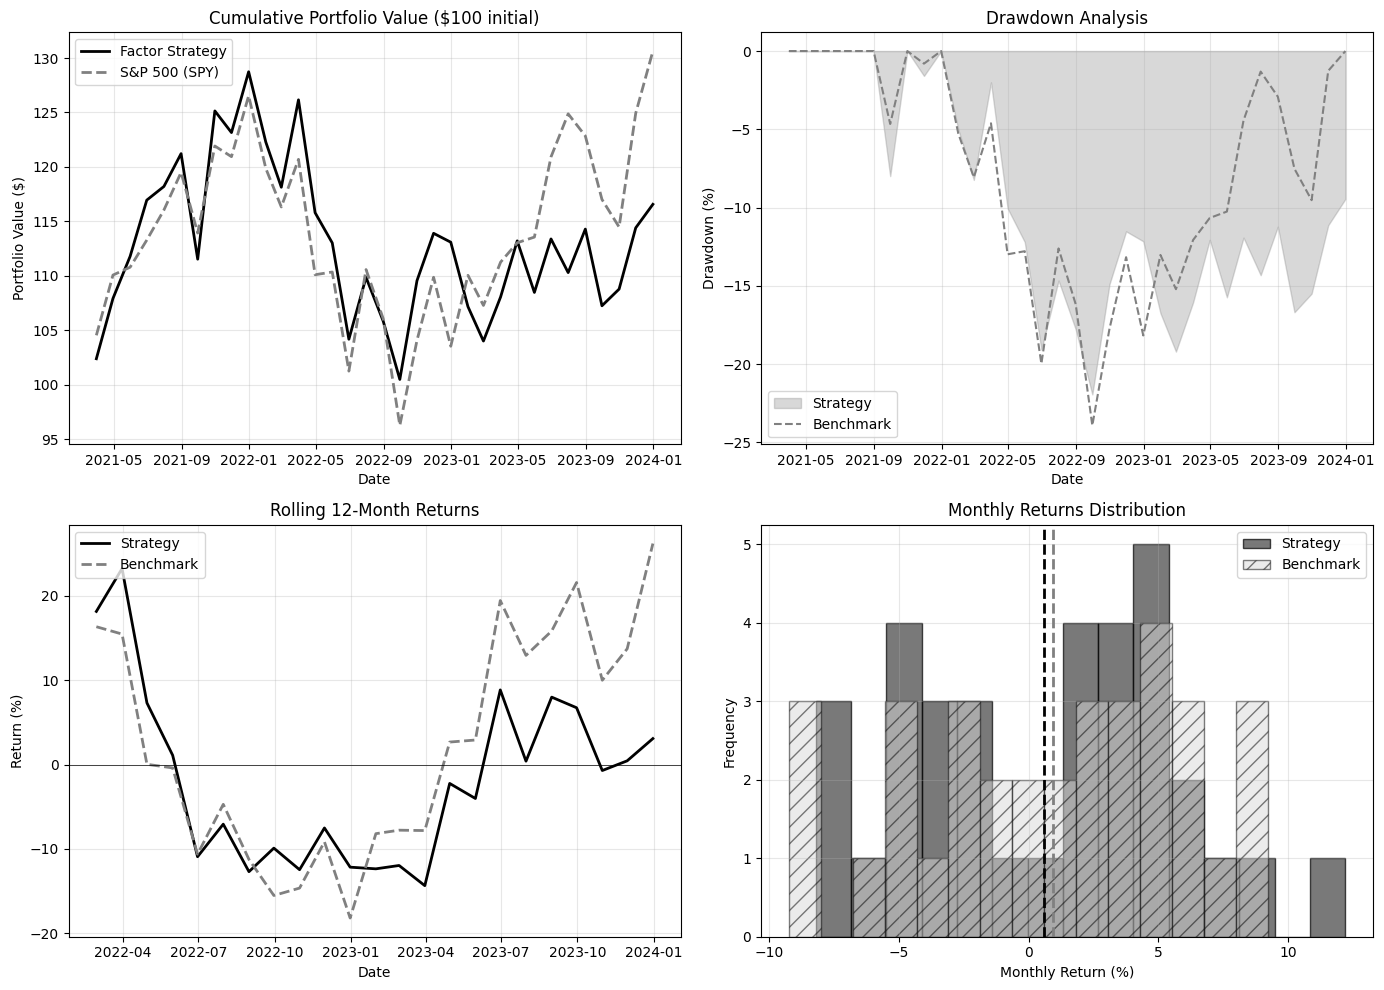


Figure saved as 'portfolio_backtest_results.png'


In [11]:
def plot_backtest_results(results, metrics):
    """Create comprehensive visualization of backtest results."""
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))

    # 1. Cumulative Returns
    ax1 = axes[0, 0]
    dates = results['dates']
    ax1.plot(dates, results['portfolio_values'][1:],
             label='Factor Strategy', linewidth=2, color='black')
    ax1.plot(dates, results['benchmark_values'][1:],
             label='S&P 500 (SPY)', linewidth=2, color='gray', linestyle='--')
    ax1.set_title('Cumulative Portfolio Value ($100 initial)', fontsize=12)
    ax1.set_xlabel('Date')
    ax1.set_ylabel('Portfolio Value ($)')
    ax1.legend(loc='upper left')
    ax1.grid(True, alpha=0.3)

    # 2. Drawdown
    ax2 = axes[0, 1]
    cumulative = np.array(results['portfolio_values'])
    running_max = np.maximum.accumulate(cumulative)
    drawdown = ((cumulative - running_max) / running_max * 100)[1:]

    bench_cumulative = np.array(results['benchmark_values'])
    bench_running_max = np.maximum.accumulate(bench_cumulative)
    bench_drawdown = ((bench_cumulative - bench_running_max) / bench_running_max * 100)[1:]

    ax2.fill_between(dates, drawdown, 0, alpha=0.3, color='0.5',
                     label='Strategy')
    ax2.plot(dates, bench_drawdown, color='gray', linestyle='--',
             label='Benchmark', linewidth=1.5)
    ax2.set_title('Drawdown Analysis', fontsize=12)
    ax2.set_xlabel('Date')
    ax2.set_ylabel('Drawdown (%)')
    ax2.legend(loc='lower left')
    ax2.grid(True, alpha=0.3)

    # 3. Rolling 12-Month Returns
    ax3 = axes[1, 0]
    port_returns = np.array(results['portfolio_returns'])
    bench_returns = np.array(results['benchmark_returns'])

    if len(port_returns) >= 12:
        rolling_port = pd.Series(port_returns).rolling(12).apply(
            lambda x: np.prod(1 + x) - 1) * 100
        rolling_bench = pd.Series(bench_returns).rolling(12).apply(
            lambda x: np.prod(1 + x) - 1) * 100

        ax3.plot(dates[11:], rolling_port.dropna(),
                 label='Strategy', linewidth=2, color='black')
        ax3.plot(dates[11:], rolling_bench.dropna(),
                 label='Benchmark', linewidth=2, color='gray', linestyle='--')
        ax3.axhline(y=0, color='black', linestyle='-', linewidth=0.5)

    ax3.set_title('Rolling 12-Month Returns', fontsize=12)
    ax3.set_xlabel('Date')
    ax3.set_ylabel('Return (%)')
    ax3.legend(loc='upper left')
    ax3.grid(True, alpha=0.3)

    # 4. Monthly Returns Distribution
    ax4 = axes[1, 1]
    ax4.hist(np.array(results['portfolio_returns']) * 100, bins=15,
             alpha=0.7, label='Strategy', color='0.25', edgecolor='black')
    ax4.hist(np.array(results['benchmark_returns']) * 100, bins=15,
             alpha=0.5, label='Benchmark', color='0.85', edgecolor='black', hatch='//')
    ax4.axvline(x=np.mean(results['portfolio_returns']) * 100,
                color='black', linestyle='--', linewidth=2)
    ax4.axvline(x=np.mean(results['benchmark_returns']) * 100,
                color='gray', linestyle='--', linewidth=2)
    ax4.set_title('Monthly Returns Distribution', fontsize=12)
    ax4.set_xlabel('Monthly Return (%)')
    ax4.set_ylabel('Frequency')
    ax4.legend(loc='upper right')
    ax4.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig('portfolio_backtest_results.png', dpi=150, bbox_inches='tight')
    plt.show()

    print("\nFigure saved as 'portfolio_backtest_results.png'")

# Generate plots
plot_backtest_results(backtest_results, strategy_metrics)

## AI Tutorial: Stock Selection and Portfolio Construction / Production Considerations / Risk Management

### Code example 11
Source line: `Overleaf/Final Project/Chapter 7 - Equity Investing and Portfolio Management/main.tex`

In [12]:
def apply_risk_limits(weights, returns, max_position=0.15, max_sector=None,
                      max_volatility=0.25, current_vol=None, sectors=None,
                      cov_method='shrinkage'):
    """Cap long-only risky weights; residual allocation stays in zero-return cash.

    returns are monthly asset returns, used to recompute volatility after caps.
    sectors maps ticker to sector and is required when max_sector is supplied.
    current_vol optionally adds a conservative volatility estimate for the
    ORIGINAL weights; it is not a substitute for recalculating the capped book.
    """
    if not np.isfinite(weights.to_numpy()).all() or (weights < 0).any() or weights.sum() > 1 + 1e-8:
        raise ValueError('Weights must be finite, long-only, and sum to at most one.')
    if not 0 < max_position <= 1 or max_volatility <= 0:
        raise ValueError('Position and volatility limits must be positive.')
    adjusted = weights.clip(upper=max_position).copy()
    # Do not renormalize: that would restore weights above the requested caps.
    if max_sector is not None:
        if not 0 < max_sector <= 1 or sectors is None:
            raise ValueError('A sector cap in (0, 1] requires a complete sector mapping.')
        sector_labels = pd.Series(sectors).reindex(adjusted.index)
        if sector_labels.isna().any():
            raise ValueError('Sector mapping is missing held assets.')
        for sector in sector_labels.unique():
            members = sector_labels.index[sector_labels == sector]
            exposure = adjusted.loc[members].sum()
            if exposure > max_sector:
                adjusted.loc[members] *= max_sector / exposure
    history = returns.loc[:, adjusted.index].dropna()
    if len(history) < 2:
        raise ValueError('At least two complete monthly returns are needed for risk estimation.')
    # Estimate risk with the same covariance the optimizer used, so the gate
    # measures the book on the basis that produced its weights. On this book
    # the two estimators differ by about three hundredths of a point, but a
    # gate has no reason to run a different risk model from the optimizer.
    covariance = estimate_covariance(history, method=cov_method)
    capped_vol = float(np.sqrt(max(0.0, adjusted.to_numpy() @ covariance.to_numpy() @ adjusted.to_numpy())))
    if current_vol is not None:
        if not np.isfinite(current_vol) or current_vol < 0:
            raise ValueError('Current volatility must be finite and nonnegative.')
        capped_vol = max(capped_vol, current_vol)
    if capped_vol > max_volatility:
        adjusted *= max_volatility / capped_vol
    return adjusted

# Example risk-adjusted weights
COV_METHOD = 'shrinkage'  # one risk model for the optimizer and the gate

# current_vol is left unset so the recomputed volatility of the capped book
# is what the limit is tested against. Passing the pre-cap volatility would
# floor the estimate at its old value and make the recomputation inert.
risk_adjusted_weights = apply_risk_limits(
    max_sharpe_result['weights'],
    selected_returns,
    max_position=0.15,
    max_volatility=0.20,
    cov_method=COV_METHOD
)

print("Risk-Adjusted Weights (max 15% position, 20% vol limit):")
print(risk_adjusted_weights.sort_values(ascending=False).round(3))
print(f'Cash weight: {1 - risk_adjusted_weights.sum():.1%}')
achieved = np.sqrt(risk_adjusted_weights @ estimate_covariance(
    selected_returns.loc[:, risk_adjusted_weights.index].dropna(),
    method=COV_METHOD) @ risk_adjusted_weights)
print(f'Estimated volatility of the capped book: {achieved:.2%}')

Risk-Adjusted Weights (max 15% position, 20% vol limit):
MSFT     0.150
LIN      0.150
SO       0.150
NVDA     0.150
MCD      0.106
JPM      0.020
GOOGL    0.020
META     0.020
AMZN     0.020
DUK      0.020
dtype: float64
Cash weight: 19.4%
Estimated volatility of the capped book: 15.90%


### Reading the computed output

Run the preceding cell for the current calculation. The old manuscript table has been removed because it was not generated by the corrected workflow and contained inconsistent rankings or arithmetic. The current fundamental snapshot is a mechanics demonstration; historical results use lagged price factors unless an as-reported fundamentals callback is supplied.


## AI Tutorial: Stock Selection and Portfolio Construction / Production Considerations / Performance Attribution

### Code example 12
Source line: `Overleaf/Final Project/Chapter 7 - Equity Investing and Portfolio Management/main.tex`

In [13]:
def factor_attribution(portfolio_returns, factor_returns, factor_names):
    """
    Decompose portfolio returns into factor contributions.

    Inputs must be monthly, with portfolio returns already in excess of cash.
    Uses regression-based attribution:
    R_portfolio = alpha + sum(beta_i * F_i) + epsilon
    """
    if set(factor_names) != set(factor_returns.columns):
        raise ValueError('Factor names must match the factor-return columns.')
    aligned = pd.concat([portfolio_returns.rename('__portfolio__'), factor_returns[factor_names]], axis=1, join='inner').dropna()
    if len(aligned) <= len(factor_names) + 1 or not np.isfinite(aligned.to_numpy()).all():
        raise ValueError('Insufficient aligned finite monthly observations for attribution.')
    X = aligned[factor_names].to_numpy()
    y = aligned['__portfolio__'].to_numpy()
    if np.linalg.matrix_rank(np.column_stack([np.ones(len(X)), X])) < len(factor_names) + 1:
        raise ValueError('Factor design is rank deficient; alpha and betas are not identifiable.')

    model = LinearRegression()
    model.fit(X, y)

    factor_betas = pd.Series(model.coef_, index=factor_names)
    alpha = model.intercept_ * 12  # Annualized
    r_squared = model.score(X, y)

    # Factor contributions (annualized)
    factor_contributions = factor_betas * aligned[factor_names].mean() * 12

    return {
        'alpha': alpha,
        'factor_betas': factor_betas,
        'factor_contributions': factor_contributions,
        'r_squared': r_squared
    }

print("\nNote: Factor attribution requires factor return time series")
print("(e.g., Fama-French factors from Kenneth French's data library)")
print("See example below for downloading and using these factors.")


Note: Factor attribution requires factor return time series
(e.g., Fama-French factors from Kenneth French's data library)
See example below for downloading and using these factors.


### Code example 13
Source line: `Overleaf/Final Project/Chapter 7 - Equity Investing and Portfolio Management/main.tex`

```python
# Download Fama-French 5 factors from Kenneth French's data library
# Available at: https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/data_library.html
# The pandas_datareader package provides convenient access:
#   pip install pandas-datareader
import pandas_datareader.data as web
import pandas_datareader.famafrench as ff

# Older pandas-datareader releases use HTTP; the library endpoint requires HTTPS.
ff._URL = 'https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/'
portfolio_returns = pd.Series(
    backtest_results['portfolio_returns'],
    index=backtest_results['dates'].to_period('M'), name='portfolio')

ff_factors = web.DataReader('F-F_Research_Data_5_Factors_2x3',
                            'famafrench',
                            start='2019-01-01',
                            end='2024-01-01')[0] / 100  # Convert from percentage

# The monthly table uses a PeriodIndex; do not align daily factor returns
# to calendar-month portfolio returns. DataReader values are percentages.
ff_factors.index = pd.PeriodIndex(ff_factors.index, freq='M')
# Align dates with portfolio returns
common_dates = portfolio_returns.index.intersection(ff_factors.index)
aligned_portfolio = portfolio_returns.loc[common_dates]
aligned_factors = ff_factors.loc[common_dates, ['Mkt-RF', 'SMB', 'HML', 'RMW', 'CMA']]

# Run factor attribution
attribution = factor_attribution(
    aligned_portfolio - ff_factors.loc[common_dates, 'RF'],  # Excess returns
    aligned_factors,
    factor_names=['Mkt-RF', 'SMB', 'HML', 'RMW', 'CMA']
)

print(f"Annualized Alpha: {attribution['alpha']:.4f}")
print(f"R-squared: {attribution['r_squared']:.4f}")
print("\nFactor Betas:")
print(attribution['factor_betas'].round(4))
print("\nAnnualized Factor Contributions:")
print(attribution['factor_contributions'].round(4))
```

Optional **monthly** factor attribution example. The HTTPS override supports older pandas-datareader releases; it uses a private module setting and may need adjustment after package updates. It needs a portfolio return series from a completed backtest and a live Kenneth French data download, so it is preserved as a listing rather than executed by default.